# Attack detection on the Fridge device (TON_IoT)
**Main models:** Decision Tree • Random Forest • XGBoost • LightGBM • CatBoost

**Baseline models (Alsaedi et al.):** LR • LDA • kNN • CART • RF • Naïve Bayes • SVM (RBF) • LSTM

## Notebook steps
1. **EDA:** understand the data with plots before any model
2. **Cleaning + 10-second windows:** clean the data and group it into 10-second windows, with context from previous windows
3. **Safe split:** hash-based blocks, shared by every device, no data leakage
4. **Training:** train 5 models and compare them
5. **Deep dive:** confusion matrix, ROC, feature importance, threshold (and recall target)
6. **Block cross-validation:** check that the result is stable and not luck
7. **Multi-class:** identify the attack type
8. **Ablation + random split demo:** check that the result is honest
9. **Anomaly score:** Z-score, Mahalanobis, Isolation Forest, Autoencoder
10. **Baseline models:** 8 classic models on the same split, binary + multi-class, full evaluation
11. **Export:** unified detection events for the aggregation step

## 3 rules against leakage and overfitting
- The `type` column is not a feature because it is the label itself (same for `date` and `time`)
- The split uses contiguous time blocks, not random rows (neighbouring rows are very similar)
- Thresholds and model choices are made on validation only, and the test set is used once at the end

In [1]:
!pip install -q catboost

In [2]:
import os, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (precision_score, recall_score, f1_score, confusion_matrix,
                             roc_curve, precision_recall_curve, roc_auc_score)
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier, early_stopping
from catboost import CatBoostClassifier

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", rc={"axes.grid.axis": "y"})
plt.rcParams["figure.dpi"] = 100
SEED = 42
SENSORS = ["fridge_temperature"]
DATA_PATH = os.environ.get("DATA_PATH", "/content/IoT_Fridge.csv")

if not os.path.exists(DATA_PATH):
    from google.colab import files
    DATA_PATH = "/content/" + list(files.upload().keys())[0]

# 1) EDA

In [3]:
raw = pd.read_csv(DATA_PATH)
print("Shape:", raw.shape)

Shape: (587076, 6)


In [4]:
raw.head()

,date,time,fridge_temperature,temp_condition,label,type
0,31-Mar-19,12:36:52,13.10,high,0,normal
1,31-Mar-19,12:36:53,8.65,high,0,normal
2,31-Mar-19,12:36:54,2.00,low,0,normal
3,31-Mar-19,12:36:55,4.80,low,0,normal
4,31-Mar-19,12:36:56,10.70,high,0,normal


In [5]:
print(raw.dtypes, "\n")

date                      str
time                      str
fridge_temperature    float64
temp_condition            str
label                   int64
type                      str
dtype: object 



In [6]:
print("Missing values:\n", raw.isna().sum(), "\n")

Missing values:
 date                  0
time                  0
fridge_temperature    0
temp_condition        0
label                 0
type                  0
dtype: int64 



In [7]:
print("Exact duplicates:", raw.duplicated().sum())

Exact duplicates: 100863


In [8]:
# the text columns contain extra spaces (e.g. "   12:36:52   ", " high"), so we strip them
for c in ["date", "time", "temp_condition", "type"]:
    raw[c] = raw[c].str.strip()

In [9]:
print("Duplicates after cleaning the text columns:", raw.duplicated().sum())

Duplicates after cleaning the text columns: 135048


In [10]:
raw[SENSORS].describe().round(2)

,fridge_temperature
count,587076.00
mean,7.15
std,3.62
min,1.00
25%,4.20
50%,6.70
75%,10.25
max,14.00


In [11]:
raw["temp_condition"].value_counts()

temp_condition
high    329979
low     257097
Name: count, dtype: int64

In [12]:
raw["label"].value_counts()

label
0    500827
1     86249
Name: count, dtype: int64

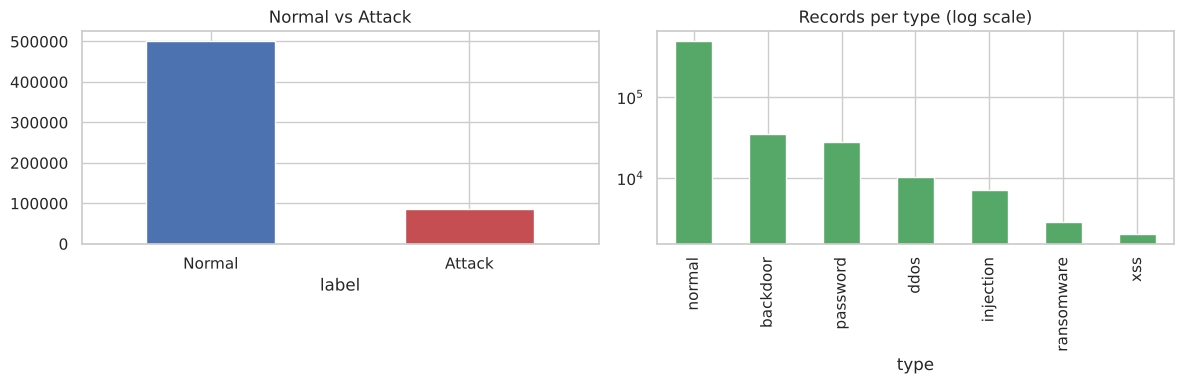

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
raw["label"].map({0: "Normal", 1: "Attack"}).value_counts().plot.bar(ax=ax[0], color=["#4c72b0", "#c44e52"], rot=0)
ax[0].set_title("Normal vs Attack")
raw["type"].value_counts().plot.bar(ax=ax[1], color="#55a868")
ax[1].set_yscale("log"); ax[1].set_title("Records per type (log scale)")
plt.tight_layout(); plt.show()

<style>
.wbox, .wbox * { color:#111111 !important; }
.wbox { background-color:#ffffff !important; border:6px solid #ffffff; border-radius:12px; padding:18px 26px; font-family:Arial, sans-serif; line-height:1.7; box-shadow:0 0 0 1px #cccccc; }
.wbox h2, .wbox h3 { margin-top:10px; }
</style>
<div class="wbox">
<h2>Class Distribution Analysis</h2>
<h3>Normal vs Attack (left chart)</h3>
<ul>
  <li>The dataset is <b>imbalanced</b>: Normal records (~500,000) are much more than Attack records (~86,000).</li>
  <li>Normal traffic is about <b>6x</b> larger than Attack traffic.</li>
  <li>A model could get high accuracy just by predicting "Normal" every time, so accuracy alone is not a good metric.</li>
</ul>
<h3>Records per type (right chart, log scale)</h3>
<ul>
  <li>The y-axis uses a <b>log scale</b> because the differences between classes are very large.</li>
  <li><b>normal</b> is the biggest class by far (~500,000 records).</li>
  <li>The attack types are also imbalanced:
    <ul>
      <li><b>backdoor</b> (~35,500) and <b>password</b> (~28,400) are the biggest attack types.</li>
      <li><b>ddos</b> (~10,200) and <b>injection</b> (~7,100) are medium-sized.</li>
      <li><b>ransomware</b> (~2,900) and <b>xss</b> (~2,000) are the smallest classes.</li>
    </ul>
  </li>
  <li>The difference between the largest attack type and the smallest is about <b>17x</b>.</li>
</ul>
<h3>Conclusion</h3>
<ul>
  <li>The data has <b>two levels of imbalance</b>: Normal vs Attack, and between the attack types themselves.</li>
  <li>Rare classes like <b>xss</b>, <b>ransomware</b> and <b>injection</b> will be hard for the model to learn.</li>
</ul>
</div>

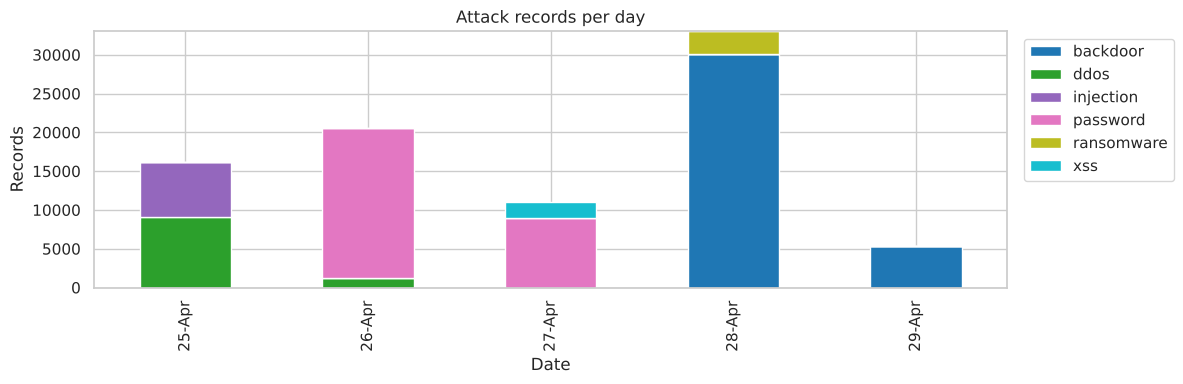

In [14]:
day = pd.to_datetime(raw["date"], format="%d-%b-%y")
att = raw[raw["label"] == 1]
pd.crosstab(day[att.index].dt.strftime("%d-%b"), att["type"]).plot.bar(stacked=True, figsize=(12, 4), colormap="tab10")
plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.title("Attack records per day"); plt.xlabel("Date"); plt.ylabel("Records"); plt.tight_layout(); plt.show()

<style>
.wbox, .wbox * { color:#111111 !important; }
.wbox { background-color:#ffffff !important; border:6px solid #ffffff; border-radius:12px; padding:18px 26px; font-family:Arial, sans-serif; line-height:1.7; box-shadow:0 0 0 1px #cccccc; }
.wbox h2, .wbox h3 { margin-top:10px; }
</style>
<div class="wbox">
<h2>Attack Records per Day Analysis</h2>

<h3>Daily volume</h3>
<ul>
  <li>The data starts on 31-Mar, but all the attacks happen over only <b>5 days</b> (25-Apr to 29-Apr).</li>
  <li>The highest day is <b>28-Apr</b> with about <b>33,000</b> attack records.</li>
  <li>The lowest day is <b>29-Apr</b> with about <b>5,400</b> records.</li>
</ul>

<h3>Attack types by day</h3>
<ul>
  <li><b>25-Apr:</b> <b>ddos</b> (~9,000) and <b>injection</b> (~7,100).</li>
  <li><b>26-Apr:</b> mostly <b>password</b> (~19,400) with a small amount of <b>ddos</b> (~1,200).</li>
  <li><b>27-Apr:</b> mostly <b>password</b> (~9,000) with a small amount of <b>xss</b> (~2,000).</li>
  <li><b>28-Apr:</b> mostly <b>backdoor</b> (~30,200) and some <b>ransomware</b> (~2,900).</li>
  <li><b>29-Apr:</b> only <b>backdoor</b> (~5,400).</li>
</ul>

<h3>Key observations</h3>
<ul>
  <li>Attacks are <b>not spread evenly</b>: each attack type is concentrated in one or two specific days, like planned attack campaigns.</li>
  <li><b>Injection</b> appears only on 25-Apr, <b>xss</b> only on 27-Apr and <b>ransomware</b> only on 28-Apr.</li>
</ul>

<h3>Conclusion and impact on modeling</h3>
<ul>
  <li>A <b>random split</b> would mix neighbouring rows of the same campaign between train and test, and a plain <b>time-based split</b> could leave some attack types completely out of one set.</li>
  <li>The date should <b>not</b> be used as a feature, because the model may learn "which day" instead of the real attack behavior (data leakage).</li>
  <li>Rare types (<b>xss</b>, <b>ransomware</b>, <b>injection</b>) exist in only one day each, so we use <b>class weights</b> and a <b>block split</b> that keeps whole time blocks together.</li>
</ul>
</div>

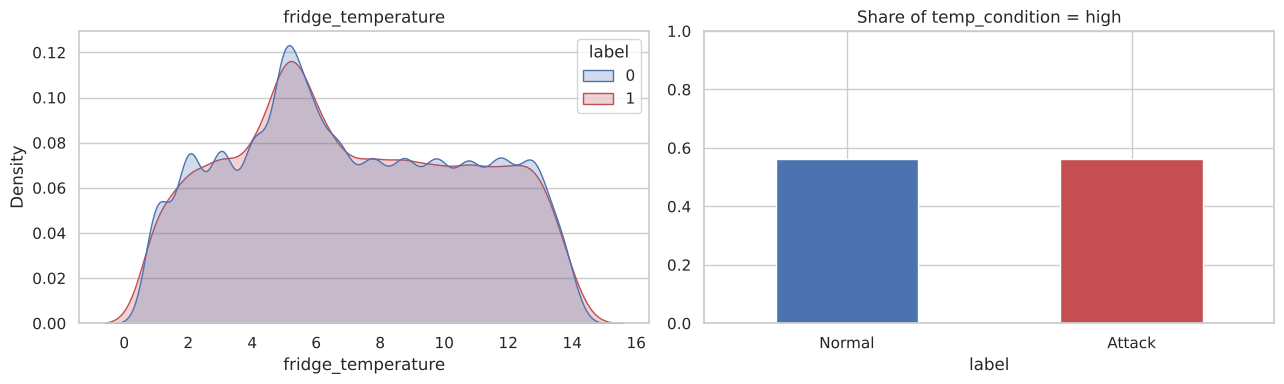

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.kdeplot(data=raw.sample(100_000, random_state=SEED), x="fridge_temperature", hue="label", common_norm=False,
            fill=True, palette=["#4c72b0", "#c44e52"], ax=ax[0])
ax[0].set_title("fridge_temperature")
(raw.groupby("label")["temp_condition"].apply(lambda s: (s == "high").mean())
    .rename(index={0: "Normal", 1: "Attack"})
    .plot.bar(ax=ax[1], color=["#4c72b0", "#c44e52"], rot=0))
ax[1].set_ylim(0, 1); ax[1].set_title("Share of temp_condition = high")
plt.tight_layout(); plt.show()

<style>
.wbox, .wbox * { color:#111111 !important; }
.wbox { background-color:#ffffff !important; border:6px solid #ffffff; border-radius:12px; padding:18px 26px; font-family:Arial, sans-serif; line-height:1.7; box-shadow:0 0 0 1px #cccccc; }
.wbox h2, .wbox h3 { margin-top:10px; }
</style>
<div class="wbox">
<h2>Feature Distribution by Label (KDE Plot)</h2>

<h3>How to read the plots</h3>
<ul>
  <li>The left plot shows the <b>density</b> (how common each value is) of <code>fridge_temperature</code>. <b>Blue (label 0)</b> = Normal, <b>Red (label 1)</b> = Attack.</li>
  <li>The right plot shows the share of rows where <code>temp_condition</code> is <b>high</b>.</li>
  <li>If the two curves overlap a lot, the feature is <b>weak</b> at separating the classes.</li>
</ul>

<h3>Temperature</h3>
<ul>
  <li>The two curves <b>overlap almost completely</b>. The values range from 1 to 14, with a peak around <b>5</b> and a flat area from 7 to 13.</li>
  <li>The mean is the same for both classes (<b>7.15</b>), and the median is almost the same (6.7 for Normal, 6.8 for Attack).</li>
</ul>

<h3>temp_condition</h3>
<ul>
  <li>The share of <b>high</b> is <b>56%</b> for Normal and <b>56%</b> for Attack, so there is no difference.</li>
</ul>

<h3>Conclusion</h3>
<ul>
  <li>The temperature value of a single row <b>cannot separate</b> Attack from Normal.</li>
  <li>The difference must come from <b>other signals</b>, like how many rows arrive in a time window, and how the values change over time.</li>
</ul>
</div>

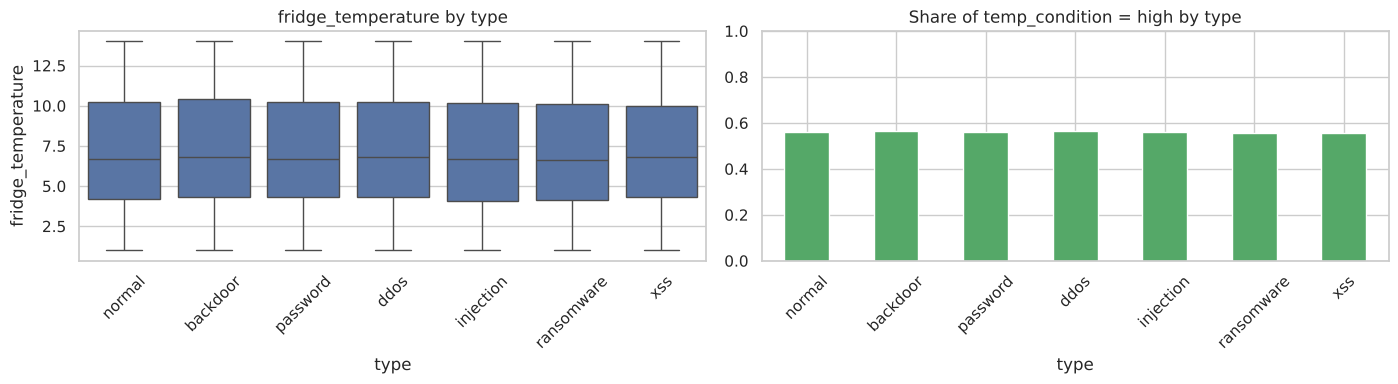

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
order = raw["type"].value_counts().index
sns.boxplot(data=raw, x="type", y="fridge_temperature", order=order, showfliers=False, ax=ax[0])
ax[0].tick_params(axis="x", rotation=45); ax[0].set_title("fridge_temperature by type")
(raw.groupby("type")["temp_condition"].apply(lambda s: (s == "high").mean()).reindex(order)
    .plot.bar(ax=ax[1], color="#55a868", rot=45))
ax[1].set_ylim(0, 1); ax[1].set_title("Share of temp_condition = high by type")
plt.tight_layout(); plt.show()

<style>
.wbox, .wbox * { color:#111111 !important; }
.wbox { background-color:#ffffff !important; border:6px solid #ffffff; border-radius:12px; padding:18px 26px; font-family:Arial, sans-serif; line-height:1.7; box-shadow:0 0 0 1px #cccccc; }
.wbox h2, .wbox h3 { margin-top:10px; }
</style>
<div class="wbox">
<h2>Feature Distribution by Attack Type (Box Plots)</h2>

<h3>How to read the plots</h3>
<ul>
  <li>The <b>line inside the box</b> is the median, and the <b>box</b> covers the middle 50% of the values.</li>
  <li>If a box is far from the <b>normal</b> box, the feature helps to separate that type from normal traffic.</li>
</ul>

<h3>Temperature</h3>
<ul>
  <li>All the types have almost the <b>same box</b>: the median is between <b>6.65 and 6.8</b> and the middle 50% is about 4 to 10.</li>
  <li>The whiskers of every type cover the same full range (1 to 14).</li>
</ul>

<h3>temp_condition</h3>
<ul>
  <li>The share of <b>high</b> is about <b>0.56</b> in every type, including normal.</li>
</ul>

<h3>Conclusion</h3>
<ul>
  <li>No attack type has a different temperature pattern from normal, so <b>none of them</b> can be found by looking at the raw value.</li>
  <li>To tell the types apart we need <b>window features</b> (mean, std, number of records) and the <b>history</b> of previous windows.</li>
</ul>
</div>

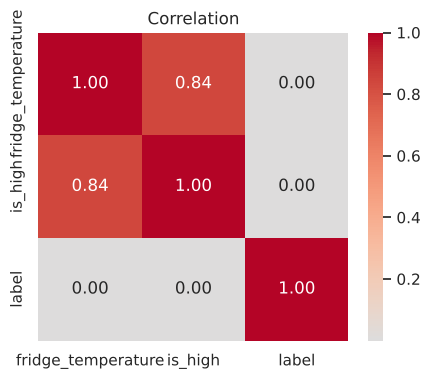

In [17]:
raw["is_high"] = (raw["temp_condition"] == "high").astype(int)
plt.figure(figsize=(5, 4))
sns.heatmap(raw[SENSORS + ["is_high", "label"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation"); plt.show()

<style>
.wbox, .wbox * { color:#111111 !important; }
.wbox { background-color:#ffffff !important; border:6px solid #ffffff; border-radius:12px; padding:18px 26px; font-family:Arial, sans-serif; line-height:1.7; box-shadow:0 0 0 1px #cccccc; }
.wbox h2, .wbox h3 { margin-top:10px; }
</style>
<div class="wbox">
<h2>Correlation Analysis</h2>

<h3>How to read the heatmap</h3>
<ul>
  <li>Values range from <b>-1 to +1</b>: +1 is a perfect positive relation, -1 is a perfect negative relation, and <b>0 means no linear relation</b>.</li>
  <li>The diagonal is always 1.00 because each column is compared with itself.</li>
  <li><code>is_high</code> is <code>temp_condition</code> turned into 0/1 (1 = high).</li>
</ul>

<h3>Features vs each other</h3>
<ul>
  <li><b>fridge_temperature</b> and <b>is_high</b> have a strong correlation (<b>0.84</b>), because <code>temp_condition</code> is mostly a high/low flag of the temperature.</li>
  <li>So <code>temp_condition</code> gives little new information beyond the temperature itself.</li>
</ul>

<h3>Features vs label</h3>
<ul>
  <li>Both <b>fridge_temperature</b> and <b>is_high</b> have a correlation of <b>0.00</b> with the label.</li>
  <li>There is <b>no linear relationship</b> between the raw values and the label.</li>
</ul>

<h3>Conclusion</h3>
<ul>
  <li>The raw row features are <b>very weak predictors</b>, which matches the KDE and box plots.</li>
  <li>The useful signal for this device is expected to be in the <b>window level</b> (number of records, change over time), so we build window features next.</li>
</ul>
</div>

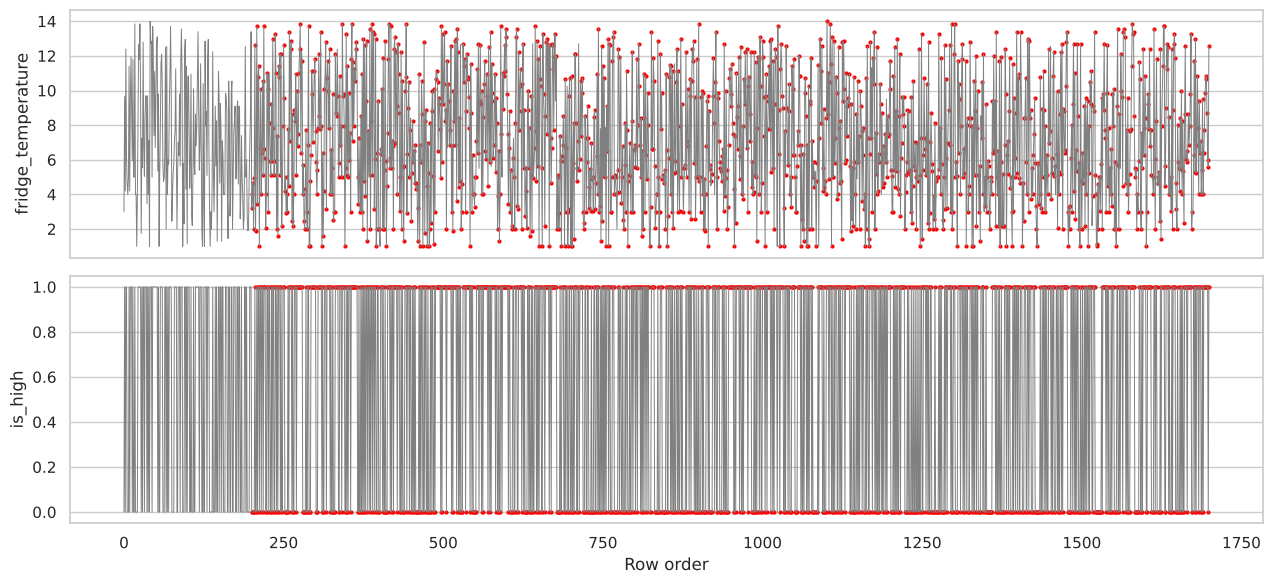

In [18]:
first = raw.index[raw["label"] == 1][0]
seg = raw.iloc[max(first - 200, 0) : first + 1500].reset_index(drop=True)
fig, ax = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
for a, c in zip(ax, SENSORS + ["is_high"]):
    a.plot(seg[c], lw=0.7, color="gray")
    a.scatter(seg.index[seg.label == 1], seg.loc[seg.label == 1, c], s=4, color="red")
    a.set_ylabel(c)
ax[-1].set_xlabel("Row order"); plt.tight_layout(); plt.show()

<style>
.wbox, .wbox * { color:#111111 !important; }
.wbox { background-color:#ffffff !important; border:6px solid #ffffff; border-radius:12px; padding:18px 26px; font-family:Arial, sans-serif; line-height:1.7; box-shadow:0 0 0 1px #cccccc; }
.wbox h2, .wbox h3 { margin-top:10px; }
</style>
<div class="wbox">
<h2>Sensor Values by Row Order (Time Series)</h2>

<h3>How to read the plot</h3>
<ul>
  <li>The top panel shows <b>fridge_temperature</b> and the bottom panel shows <b>is_high</b> across the row order of the data.</li>
  <li>The <b>gray line</b> is the value, and the <b>red dots</b> mark the <b>Attack</b> rows (label 1).</li>
</ul>

<h3>What we see</h3>
<ul>
  <li><b>Rows 0 to ~200:</b> normal data, with no red dots. The temperature jumps between about 1 and 14 all the time.</li>
  <li><b>From row ~200:</b> the red dots start and they appear <b>everywhere</b> on the line, at low, middle and high temperatures.</li>
  <li>The line has the <b>same jumping behavior</b> before and after the attack starts, and <code>is_high</code> flips between 0 and 1 all the time in both parts.</li>
</ul>

<h3>Key observations</h3>
<ul>
  <li>The temperature of an attack row looks the <b>same</b> as a normal row, so the attack is not visible in the value itself.</li>
  <li>This matches the KDE, box plots and correlation (almost no difference).</li>
</ul>

<h3>Conclusion and impact on modeling</h3>
<ul>
  <li>The attack changes <b>how the records arrive</b> (the number of rows per time window), not the temperature value.</li>
  <li>Do <b>not</b> use row index or date as a feature, because it can cause <b>data leakage</b>.</li>
  <li>Use <b>10-second window features</b> and <b>lag / rolling features</b> from the previous windows.</li>
</ul>
</div>

<style>
.wbox, .wbox * { color:#111111 !important; }
.wbox { background-color:#ffffff !important; border:6px solid #ffffff; border-radius:12px; padding:18px 26px; font-family:Arial, sans-serif; line-height:1.7; box-shadow:0 0 0 1px #cccccc; }
.wbox h2, .wbox h3 { margin-top:10px; }
</style>
<div class="wbox">
<h2>EDA Summary: What We Learned</h2>

<ul>
  <li><b>Imbalanced data:</b> Normal records are about <b>6x</b> more than Attack records, and some attack types (<b>xss</b>, <b>ransomware</b>, <b>injection</b>) are very rare.</li>
  <li><b>Attacks depend on the day:</b> all attacks are between 25-Apr and 29-Apr, and each attack type appears in only one or two specific days.</li>
  <li><b>No signal in the raw value:</b> the temperature has the same distribution in Normal and Attack (mean 7.15 for both), and its correlation with the label is <b>0.00</b>.</li>
  <li><b>No difference between attack types:</b> every type has almost the same temperature box and the same share of <code>high</code> (~56%).</li>
  <li><b>Redundant feature:</b> <code>temp_condition</code> is strongly related to the temperature (0.84), so it adds little new information.</li>
  <li><b>Dirty text columns:</b> the text columns have extra spaces, and removing them (and the duplicates) is important before any grouping.</li>
  <li><b>The real signal is in the timing:</b> the number of records per window is different between Normal and Attack (see step 2), so the window and history features are the key for this device.</li>
</ul>
</div>

# 2) Cleaning + 10-Second Windows

In [19]:
df = raw.drop_duplicates().reset_index(drop=True)
print(f"Rows: {len(raw)} -> {len(df)} after removing duplicates")
#Remove exact duplicate rows and print the number of rows before and after

# is_high is needed by the window features below (do not depend on the EDA cell)
df["is_high"] = (df["temp_condition"] == "high").astype(int)


Rows: 587076 -> 452028 after removing duplicates


In [20]:
ts = pd.to_datetime(df["date"] + " " + df["time"], format="%d-%b-%y %H:%M:%S")
#Combine date and time into one timestamp ts

In [21]:
df["chunk"] = (ts.diff().dt.total_seconds() < 0).cumsum()
df["win"] = ((ts - pd.Timestamp("2019-01-01")).dt.total_seconds() // 10).astype(int)
#The file is made of several time parts stuck together. When the time goes backward, a new part chunk starts.
#Chunks keep us from mixing rows that are not really consecutive.
#Create 10-second windows
#Convert the time to seconds and divide by 10, so all rows in the same 10 seconds get the same win number

In [22]:
g = df.groupby(["chunk", "win"], sort=False)
W = g[SENSORS].agg(["mean", "std", "min", "max"])
W.columns = [f"{a}_{b}" for a, b in W.columns]
W["frac_high"] = g["is_high"].mean()
W["n_records"] = g.size()
#For the sensor (fridge_temperature) we calculate mean, std, min, max in each window.
#frac_high is the share of rows in the window where temp_condition = high.
#n_records is the number of rows in the window. It can help detect attacks like ddos that increase traffic.


In [23]:
# Count how many rows of each type (normal, ddos, ...) are inside each window
counts = pd.crosstab([df["chunk"], df["win"]], df["type"]).reindex(W.index)
# The window label = the most common type inside the window (majority vote)
W["type"] = counts.idxmax(axis=1).values
# Binary label: 1 if the window is an attack, 0 if it is normal
W["is_attack"] = (W["type"] != "normal").astype(int)
# Turn chunk and win from index back into normal columns, and fill missing values with 0
W = W.reset_index().fillna(0)

In [24]:
# Number of records in the previous window (same chunk only)
W["prev_n_records"] = W.groupby("chunk")["n_records"].shift(1).fillna(0)
# Time gap (in windows) between this window and the previous one
W["gap_prev"] = W.groupby("chunk")["win"].diff().fillna(0)

In [25]:
# Loop over the main columns we want to add history for
for c in ["fridge_temperature_mean", "fridge_temperature_std", "frac_high", "n_records"]:

    # Lag features: the value of this column 1, 2, and 3 windows ago
    for k in (1, 2, 3):
        W[f"{c}_lag{k}"] = W.groupby("chunk")[c].shift(k)

    # Rolling mean: average of the previous 3 windows (shift(1) excludes the current window)
    W[f"{c}_roll3"] = W.groupby("chunk")[c].transform(lambda s: s.shift(1).rolling(3, min_periods=1).mean())

    # Change feature: current value minus the recent average (shows sudden changes)
    W[f"{c}_chg"] = W[c] - W[f"{c}_roll3"]

# Fill the missing values (first windows of each chunk have no history) with 0
W = W.fillna(0)

# Use all columns as features except the identifiers (chunk, win) and the labels (type, is_attack)
FEATURES = [c for c in W.columns if c not in ("chunk", "win", "type", "is_attack")]

# Print: number of windows, percentage of attack windows, and number of features
print(f"Windows: {len(W)} | Attack windows: {W.is_attack.mean():.1%} | Features: {len(FEATURES)}")

Windows: 51047 | Attack windows: 31.2% | Features: 28


In [26]:
W.head()

,chunk,win,fridge_temperature_mean,fridge_temperature_std,fridge_temperature_min,fridge_temperature_max,frac_high,n_records,type,is_attack,...,frac_high_lag1,frac_high_lag2,frac_high_lag3,frac_high_roll3,frac_high_chg,n_records_lag1,n_records_lag2,n_records_lag3,n_records_roll3,n_records_chg
0,0,773501,7.254545,4.169859,2.0,13.10,0.545455,11,normal,0,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.000000
1,0,773502,6.971667,3.953734,1.0,13.55,0.566667,30,normal,0,...,0.545455,0.000000,0.000000,0.545455,0.021212,11.0,0.0,0.0,11.000000,19.000000
2,0,773503,6.943000,3.694549,1.0,12.85,0.560000,50,normal,0,...,0.566667,0.545455,0.000000,0.556061,0.003939,30.0,11.0,0.0,20.500000,29.500000
3,0,773504,6.942857,3.652379,1.0,14.00,0.528571,70,normal,0,...,0.560000,0.566667,0.545455,0.557374,-0.028802,50.0,30.0,11.0,30.333333,39.666667
4,0,773505,7.142353,3.556738,1.0,13.70,0.600000,85,normal,0,...,0.528571,0.560000,0.566667,0.551746,0.048254,70.0,50.0,30.0,50.000000,35.000000


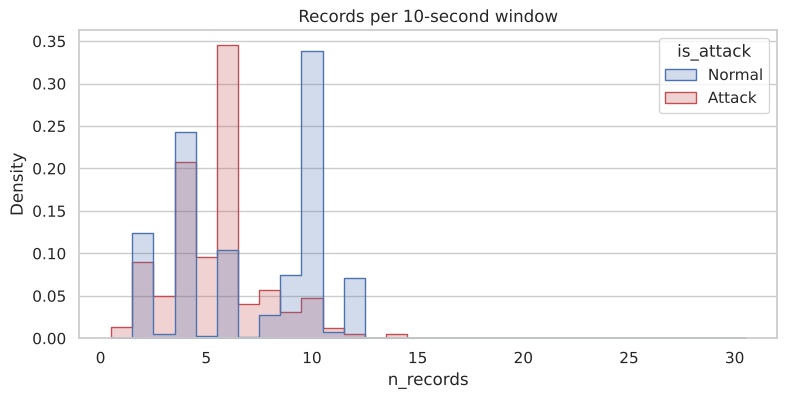

In [27]:
plt.figure(figsize=(9, 4))
sns.histplot(data=W[W.n_records <= 30], x="n_records", hue=W["is_attack"].map({0: "Normal", 1: "Attack"}),
             stat="density", common_norm=False, discrete=True, palette=["#4c72b0", "#c44e52"], element="step")
plt.title("Records per 10-second window"); plt.show()

<style>
.wbox, .wbox * { color:#111111 !important; }
.wbox { background-color:#ffffff !important; border:6px solid #ffffff; border-radius:12px; padding:18px 26px; font-family:Arial, sans-serif; line-height:1.7; box-shadow:0 0 0 1px #cccccc; }
.wbox h2, .wbox h3 { margin-top:10px; }
</style>
<div class="wbox">
<h2>Result: Records per 10-Second Window</h2>
<ul>
  <li><b>Normal windows</b> are mostly at <b>10 records</b> (about one third of them), with other groups at <b>4</b> (about a quarter), <b>2</b> and <b>12</b>.</li>
  <li><b>Attack windows</b> are mostly at <b>6 records</b> (about one third of them), with other groups at <b>4</b> and <b>2</b>.</li>
  <li>Windows with <b>10 or 12 records</b> are mostly Normal, and windows with <b>6 records</b> are mostly Attack, so rows are often <b>missing</b> during attacks.</li>
  <li>The two classes <b>overlap</b> at 2 and 4 records, so <code>n_records</code> is useful but <b>not enough alone</b>.</li>
  <li>The plot is cut at 30 records, and some windows have <b>more than 30 records</b> that are not shown here.</li>
  <li>This supports using <b>n_records</b> and its <b>lag / rolling</b> versions as features.</li>
</ul>
</div>

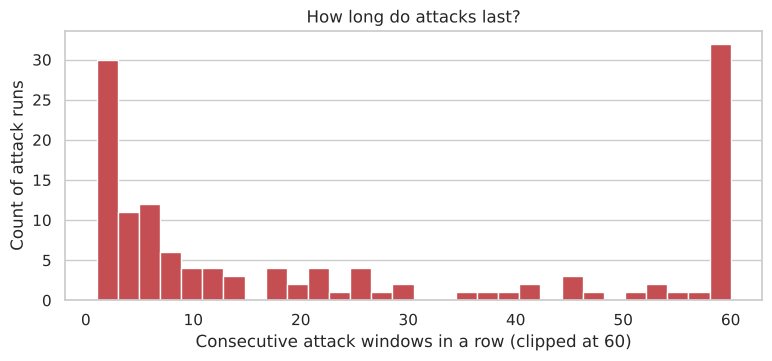

Median run = 12 windows | longest = 2404 windows


In [28]:
run_id = (W["is_attack"] != W["is_attack"].shift()).cumsum()
run_len = W[W.is_attack == 1].groupby(run_id).size()
plt.figure(figsize=(9, 3.5))
plt.hist(run_len.clip(upper=60), bins=30, color="#c44e52")
plt.xlabel("Consecutive attack windows in a row (clipped at 60)"); plt.ylabel("Count of attack runs")
plt.title("How long do attacks last?"); plt.show()
print(f"Median run = {run_len.median():.0f} windows | longest = {run_len.max()} windows")

<style>
.wbox, .wbox * { color:#111111 !important; }
.wbox { background-color:#ffffff !important; border:6px solid #ffffff; border-radius:12px; padding:18px 26px; font-family:Arial, sans-serif; line-height:1.7; box-shadow:0 0 0 1px #cccccc; }
.wbox h2, .wbox h3 { margin-top:10px; }
</style>
<div class="wbox">
<h2>How Long Do Attacks Last?</h2>

<h3>How to read the plot</h3>
<ul>
  <li>X-axis: the number of <b>consecutive attack windows</b> in a row (each window = 10 seconds). Values above 60 are <b>clipped</b> to 60.</li>
  <li>Y-axis: the <b>count of attack runs</b> (how many separate attack periods have this length).</li>
</ul>

<h3>What we see</h3>
<ul>
  <li><b>Very short attacks:</b> the first bar (1-2 windows) has about <b>30 runs</b>.</li>
  <li><b>Medium attacks:</b> the number of runs goes down quickly after 5 windows, and between 10 and 55 windows there are only 1 to 4 runs for each length.</li>
  <li><b>Very long attacks:</b> the last bar (<b>60+</b> windows) is the highest, with about <b>32 runs</b>, which means 10 minutes or more.</li>
  <li>The median run is <b>12 windows</b> (2 minutes) and the longest run is <b>2,404 windows</b> (about 6.7 hours).</li>
  <li>The distribution has a <b>U shape</b>: many very short and very long attacks, few in the middle.</li>
</ul>

<h3>Conclusion</h3>
<ul>
  <li>Attacks usually <b>continue for many windows</b>, which supports using <b>lag and rolling features</b> from previous windows.</li>
  <li>Very short attacks (1-2 windows) have little history, so they will be <b>harder to detect</b>.</li>
  <li>Neighboring windows inside one attack are very similar, so the train/test split should be by <b>blocks</b>, not random, to avoid leakage.</li>
</ul>
</div>

# 3) Safe Split

In [29]:
# ---------- Hash-based block split (same rule on every device) ----------
import hashlib

BLOCK = 100                              # windows per block
SALT = "iot-anomaly"                     # shared salt, identical on every device
TRAIN_PCT, VAL_PCT = 70, 15              # hash buckets: [0,70) train, [70,85) val, [85,100) test

n = len(W)                               # total number of windows
all_idx = np.arange(n)                   # index of every window
types = W["type"].values                 # attack type of every window
n_types = W["type"].nunique()            # number of types

def assign_split(win, bw=BLOCK, salt=SALT):
    block = np.asarray(win) // bw        # absolute block number counted from the epoch, same on every device
    bucket = {b: int(hashlib.md5(f"{salt}:{b}".encode()).hexdigest(), 16) % 100 for b in np.unique(block)}
    r = np.array([bucket[b] for b in block])
    return np.where(r < TRAIN_PCT, "train", np.where(r < TRAIN_PCT + VAL_PCT, "val", "test"))

block_id = W["win"].values // BLOCK
split_name = assign_split(W["win"].values)
train, val, test = (np.where(split_name == s)[0] for s in ("train", "val", "test"))

# Remove the first 3 and last 3 windows of every block (safety gap),
# because lag / rolling features look at the previous 3 windows
pos = W["win"].values % BLOCK
edge = (pos < 3) | (pos >= BLOCK - 3)
train, val, test = [i[~edge[i]] for i in (train, val, test)]

# Safety check: no block is shared between two sets
assert not set(block_id[train]) & set(block_id[val])
assert not set(block_id[train]) & set(block_id[test])
assert not set(block_id[val])   & set(block_id[test])

# Features (X) and labels (y)
X, y = W[FEATURES], W["is_attack"].values
y_tr, y_va, y_te = y[train], y[val], y[test]

# Summary 1: number of windows and attack percentage in each set
display(pd.DataFrame(
    {"windows":  [len(train), len(val), len(test)],
     "attack %": [y_tr.mean() * 100, y_va.mean() * 100, y_te.mean() * 100]},
    index=["train", "val", "test"]
).round(1))

# Summary 2: number of windows of each type in each set
pd.DataFrame({
    "train": W["type"].iloc[train].value_counts(),
    "val":   W["type"].iloc[val].value_counts(),
    "test":  W["type"].iloc[test].value_counts(),
}).fillna(0).astype(int)

,windows,attack %
train,33908,31.5
val,6819,25.2
test,7245,35.0


,train,val,test
type,,,
backdoor,4458,752,1405
ddos,2390,292,262
injection,613,58,2
normal,23226,5100,4706
password,2860,453,639
ransomware,188,93,231
xss,173,71,0


<li>There is <b>no leakage</b>, because every block stays in only one set.</li>
  <li>The attack percentage is different between the sets (train 31.5%, val 25.2%, test 35.0%), because whole blocks (and so whole attack campaigns) go to one set.</li>
  <li>The model can learn <b>xss</b> (173 train windows) but it <b>cannot be evaluated</b> on it, because there is no xss window in the test set.</li>
  <li><b>injection</b> has only 2 windows in the test set, so its multi-class result is not meaningful.</li>
  <li>For the binary target (<code>is_attack</code>) the effect is small, since validation and test contain many attack windows of other types.</li>

# 4) Model

In [30]:
spw = (y_tr == 0).sum() / (y_tr == 1).sum()

def make_models(spw):
    return {
        "DecisionTree": DecisionTreeClassifier(max_depth=10, min_samples_leaf=20, class_weight="balanced", random_state=SEED),
        "RandomForest": RandomForestClassifier(n_estimators=200, max_depth=12, min_samples_leaf=10,
                                               class_weight="balanced_subsample", n_jobs=-1, random_state=SEED),
        "XGBoost": XGBClassifier(n_estimators=1000, learning_rate=0.05, max_depth=5, min_child_weight=5,
                                 subsample=0.8, colsample_bytree=0.8, reg_lambda=5, scale_pos_weight=spw,
                                 early_stopping_rounds=50, eval_metric="aucpr", n_jobs=-1, random_state=SEED),
        "LightGBM": LGBMClassifier(n_estimators=1000, learning_rate=0.05, num_leaves=31, min_child_samples=20,
                                   subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=5,
                                   class_weight="balanced", n_jobs=-1, random_state=SEED, verbose=-1),
        "CatBoost": CatBoostClassifier(iterations=600, learning_rate=0.08, depth=6, l2_leaf_reg=5,
                                       auto_class_weights="Balanced", early_stopping_rounds=50,
                                       random_seed=SEED, verbose=0),
    }

def fit(name, model, Xtr, ytr, Xva, yva, sample_weight=None):

    if name == "XGBoost":
        model.fit(Xtr, ytr, sample_weight=sample_weight, eval_set=[(Xva, yva)], verbose=False)
    elif name == "LightGBM":
        model.fit(Xtr, ytr, sample_weight=sample_weight, eval_set=[(Xva, yva)], callbacks=[early_stopping(50, verbose=False)])
    elif name == "CatBoost":
        model.fit(Xtr, ytr, sample_weight=sample_weight, eval_set=(Xva, yva))
    else:
        model.fit(Xtr, ytr, sample_weight=sample_weight)
    return model

def best_threshold(y_true, proba):
    ths = np.linspace(0.05, 0.95, 91)
    return ths[np.argmax([f1_score(y_true, proba >= t) for t in ths])]

In [31]:
models, probs, rows = {}, {}, []
for name, m in make_models(spw).items():
    m = fit(name, m, X.iloc[train], y_tr, X.iloc[val], y_va)
    p_tr, p_va, p_te = (m.predict_proba(X.iloc[i])[:, 1] for i in (train, val, test))
    th = best_threshold(y_va, p_va)                       # threshold chosen on validation only
    models[name], probs[name] = m, dict(train=p_tr, val=p_va, test=p_te, th=th)

    # same metrics for train and test
    for split, y_true, p in (("train", y_tr, p_tr), ("test", y_te, p_te)):
        rows.append(dict(model=name, split=split, threshold=round(th, 2),
                         recall=recall_score(y_true, p >= th),
                         precision=precision_score(y_true, p >= th),
                         f1=f1_score(y_true, p >= th),
                         auc=roc_auc_score(y_true, p)))

results = pd.DataFrame(rows).round(3)

# side-by-side table: train vs test for each model
cmp = results.pivot(index="model", columns="split", values=["recall", "precision", "f1", "auc"])
cmp[("f1", "gap")] = cmp[("f1", "train")] - cmp[("f1", "test")]   # overfitting gap
cmp.round(3)

recall        precision            f1           auc            f1
split          test  train      test  train   test  train   test  train    gap
model                                                                         
CatBoost      0.861  0.832     0.930  0.948  0.894  0.886  0.968  0.978 -0.008
DecisionTree  0.853  0.810     0.922  0.934  0.886  0.868  0.964  0.951 -0.018
LightGBM      0.866  0.930     0.924  0.967  0.894  0.948  0.969  0.997  0.054
RandomForest  0.866  0.816     0.926  0.934  0.895  0.871  0.973  0.963 -0.024
XGBoost       0.863  0.813     0.920  0.923  0.890  0.865  0.970  0.948 -0.025

# 5) Best model analysis

In [32]:
# Choose the best model by validation F1 (the test set is not used for selection)
best = max(probs, key=lambda n: f1_score(y_va, probs[n]["val"] >= probs[n]["th"]))
print("Best model by validation F1:", best)

pt, th = probs[best]["test"], probs[best]["th"]   # test probabilities and threshold of the best model

Best model by validation F1: LightGBM


In [33]:
# Probability calibration: fitted on validation only.
# Class weights distort raw probabilities, so we map them to calibrated attack probabilities.
from sklearn.isotonic import IsotonicRegression

calibrator = IsotonicRegression(out_of_bounds="clip").fit(probs[best]["val"], y_va)

p_cal_va = calibrator.predict(probs[best]["val"])
p_cal_te = calibrator.predict(probs[best]["test"])
th_cal = best_threshold(y_va, p_cal_va)            # threshold chosen on validation only

print(f"Calibrated threshold: {th_cal:.2f}")
print(f"Test F1 (calibrated): {f1_score(y_te, p_cal_te >= th_cal):.3f}")

Calibrated threshold: 0.41
Test F1 (calibrated): 0.894


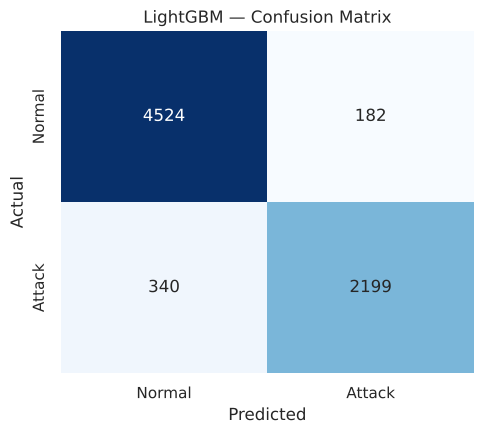

In [34]:
# Confusion matrix of the best model
cm = confusion_matrix(y_te, pt >= th)

plt.figure(figsize=(5, 4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Normal", "Attack"], yticklabels=["Normal", "Attack"])
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.title(f"{best} — Confusion Matrix")
plt.tight_layout(); plt.show()

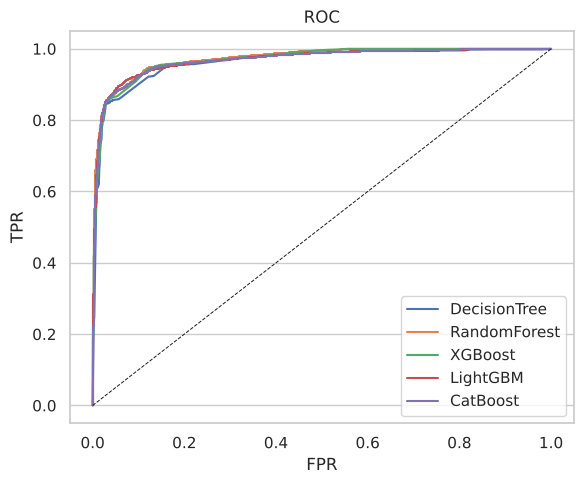

In [35]:
# ROC curve for all models
plt.figure(figsize=(6, 5))
for nm, d in probs.items():
    fpr, tpr, _ = roc_curve(y_te, d["test"])
    plt.plot(fpr, tpr, label=nm)
plt.plot([0, 1], [0, 1], "k--", lw=0.7)       # random guess line
plt.title("ROC"); plt.xlabel("FPR"); plt.ylabel("TPR"); plt.legend()
plt.tight_layout(); plt.show()

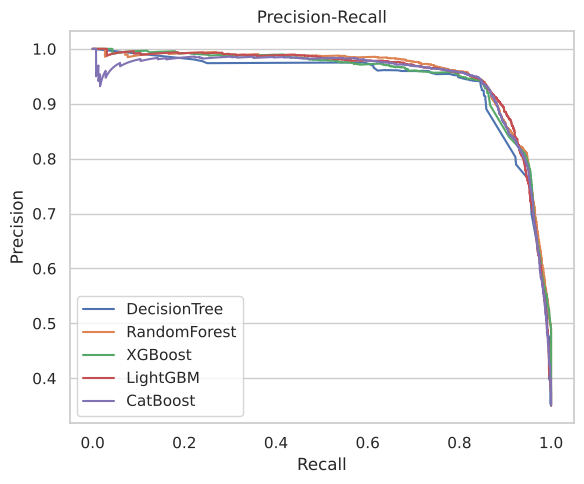

In [36]:
# Precision-Recall curve for all models
plt.figure(figsize=(6, 5))
for nm, d in probs.items():
    p, r, _ = precision_recall_curve(y_te, d["test"])
    plt.plot(r, p, label=nm)
plt.title("Precision-Recall"); plt.xlabel("Recall"); plt.ylabel("Precision"); plt.legend()
plt.tight_layout(); plt.show()

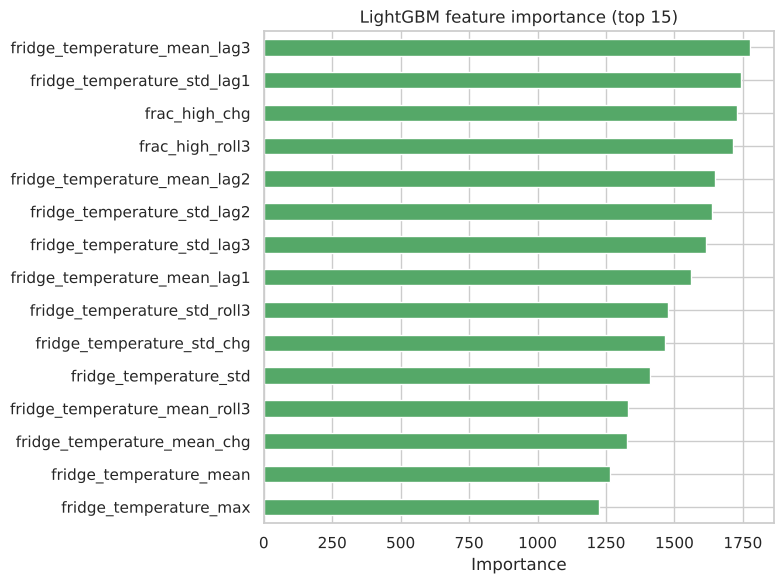

In [37]:
imp = pd.Series(models[best].feature_importances_, index=FEATURES).sort_values(ascending=False)
imp.head(15)[::-1].plot.barh(figsize=(8, 6), color="#55a868")
plt.title(f"{best} feature importance (top 15)")
plt.xlabel("Importance")
plt.tight_layout(); plt.show()

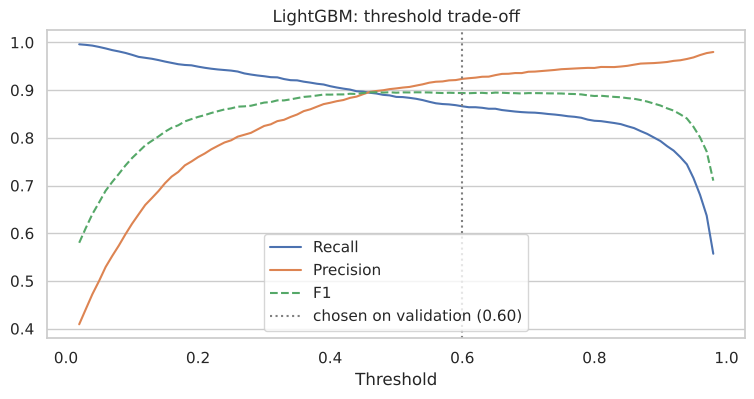

,target_recall,threshold,test_recall,test_precision,test_f1
0,0.90,0.30,0.929,0.825,0.874
1,0.95,0.13,0.966,0.674,0.794


In [38]:
ths = np.linspace(0.02, 0.98, 97)
rec = [recall_score(y_te, pt >= t) for t in ths]
pre = [precision_score(y_te, pt >= t, zero_division=1) for t in ths]
f1s = [f1_score(y_te, pt >= t) for t in ths]
plt.figure(figsize=(9, 4))
plt.plot(ths, rec, label="Recall"); plt.plot(ths, pre, label="Precision"); plt.plot(ths, f1s, label="F1", ls="--")
plt.axvline(th, color="gray", ls=":", label=f"chosen on validation ({th:.2f})")
plt.xlabel("Threshold"); plt.legend(); plt.title(f"{best}: threshold trade-off"); plt.show()

pv = probs[best]["val"]; out = []
for target in (0.90, 0.95):
    ok = [t for t in ths if recall_score(y_va, pv >= t) >= target]
    t = max(ok) if ok else ths[0]
    out.append(dict(target_recall=target, threshold=round(t, 2), test_recall=recall_score(y_te, pt >= t),
                    test_precision=precision_score(y_te, pt >= t), test_f1=f1_score(y_te, pt >= t)))
pd.DataFrame(out).round(3)

# 6) Cross-Validation

In [39]:
cv_rows = []
outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
for fold, (tr_i, te_i) in enumerate(outer.split(all_idx, W["type"].values, groups=block_id)):
    tr_i, te_i = tr_i[~edge[tr_i]], te_i[~edge[te_i]]
    inner = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
    a, b = next(inner.split(tr_i, W["type"].values[tr_i], groups=block_id[tr_i]))
    fit_i, va_i = tr_i[a], tr_i[b]
    spw_k = (y[fit_i] == 0).sum() / (y[fit_i] == 1).sum()
    for name, m in make_models(spw_k).items():
        m = fit(name, m, X.iloc[fit_i], y[fit_i], X.iloc[va_i], y[va_i])
        th_k = best_threshold(y[va_i], m.predict_proba(X.iloc[va_i])[:, 1])
        pred = m.predict_proba(X.iloc[te_i])[:, 1] >= th_k
        cv_rows.append(dict(fold=fold, model=name, recall=recall_score(y[te_i], pred),
                            precision=precision_score(y[te_i], pred), f1=f1_score(y[te_i], pred)))
    print("fold", fold, "done")
cv_df = pd.DataFrame(cv_rows)
cv_summary = cv_df.groupby("model")[["recall", "precision", "f1"]].agg(["mean", "std"]).round(3)
cv_summary

fold 0 done


fold 1 done


fold 2 done


fold 3 done


fold 4 done


recall        precision            f1       
               mean    std      mean    std   mean    std
model                                                    
CatBoost      0.829  0.028     0.876  0.120  0.847  0.054
DecisionTree  0.819  0.031     0.873  0.127  0.839  0.056
LightGBM      0.828  0.025     0.896  0.072  0.859  0.031
RandomForest  0.827  0.028     0.878  0.123  0.846  0.057
XGBoost       0.827  0.028     0.872  0.120  0.844  0.057

# 7) Multi-Class:

In [40]:
le = LabelEncoder().fit(W["type"]); classes = list(le.classes_)
yc = le.transform(W["type"]); yc_tr, yc_va, yc_te = yc[train], yc[val], yc[test]
sw = compute_sample_weight("balanced", yc_tr)
print("Test support:", dict(pd.Series(W["type"].values[test]).value_counts()))

mc = {
    "DecisionTree": DecisionTreeClassifier(max_depth=10, min_samples_leaf=20, class_weight="balanced", random_state=SEED),
    "RandomForest": RandomForestClassifier(n_estimators=200, max_depth=12, min_samples_leaf=10, class_weight="balanced_subsample", n_jobs=-1, random_state=SEED),
    "XGBoost": XGBClassifier(n_estimators=600, learning_rate=0.07, max_depth=5, min_child_weight=3, subsample=0.8, colsample_bytree=0.8,
                             reg_lambda=5, early_stopping_rounds=40, n_jobs=-1, random_state=SEED),
    "LightGBM": LGBMClassifier(n_estimators=600, learning_rate=0.07, num_leaves=31, min_child_samples=15, subsample=0.8, subsample_freq=1,
                               colsample_bytree=0.8, reg_lambda=5, class_weight="balanced", n_jobs=-1, random_state=SEED, verbose=-1),
    "CatBoost": CatBoostClassifier(iterations=500, learning_rate=0.1, depth=6, l2_leaf_reg=5, loss_function="MultiClass",
                                   auto_class_weights="Balanced", early_stopping_rounds=40, random_seed=SEED, verbose=0),
}
present = sorted(set(yc_te)); mc_pred, mc_rows = {}, []
for name, m in mc.items():

    m = fit(name, m, X.iloc[train], yc_tr, X.iloc[val], yc_va, sample_weight=sw if name == "XGBoost" else None)
    pred = np.asarray(m.predict(X.iloc[test])).ravel().astype(int); mc_pred[name] = pred
    mc_rows.append(dict(model=name, macro_f1=f1_score(yc_te, pred, labels=present, average="macro", zero_division=0),
                        weighted_f1=f1_score(yc_te, pred, average="weighted", zero_division=0)))
mc_results = pd.DataFrame(mc_rows).set_index("model").round(3)
mc_results

Test support: {'normal': np.int64(4706), 'backdoor': np.int64(1405), 'password': np.int64(639), 'ddos': np.int64(262), 'ransomware': np.int64(231), 'injection': np.int64(2)}


,macro_f1,weighted_f1
model,,
DecisionTree,0.508,0.696
RandomForest,0.514,0.779
XGBoost,0.534,0.846
LightGBM,0.552,0.876
CatBoost,0.521,0.722


Best multi-class model: LightGBM


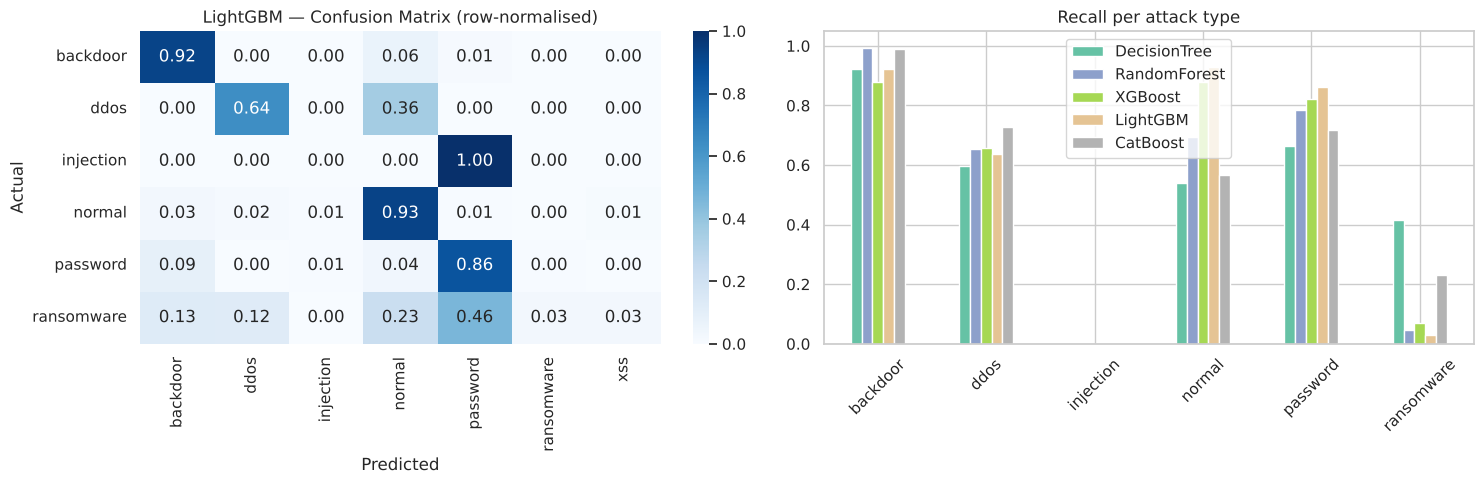

In [41]:
# choose the multi-class model by validation macro-F1 (the test set is not used for selection)
val_f1 = {n: f1_score(yc_va, np.asarray(m.predict(X.iloc[val])).ravel().astype(int),
                      labels=sorted(set(yc_va)), average="macro") for n, m in mc.items()}
best_mc = max(val_f1, key=val_f1.get); print("Best multi-class model:", best_mc)
pred = mc_pred[best_mc]

cm = confusion_matrix(yc_te, pred, labels=range(len(classes)))[present]
cm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", ax=ax[0], xticklabels=classes, yticklabels=[classes[i] for i in present])
ax[0].set_xlabel("Predicted"); ax[0].set_ylabel("Actual"); ax[0].set_title(f"{best_mc} — Confusion Matrix (row-normalised)")

per_class = pd.DataFrame({m: [(p[yc_te == k] == k).mean() for k in present] for m, p in mc_pred.items()},
                         index=[classes[i] for i in present])
per_class.plot.bar(ax=ax[1], rot=45, colormap="Set2"); ax[1].set_title("Recall per attack type"); ax[1].set_ylim(0, 1.05)
plt.tight_layout(); plt.show()

# 8) (Ablation + Random Split)

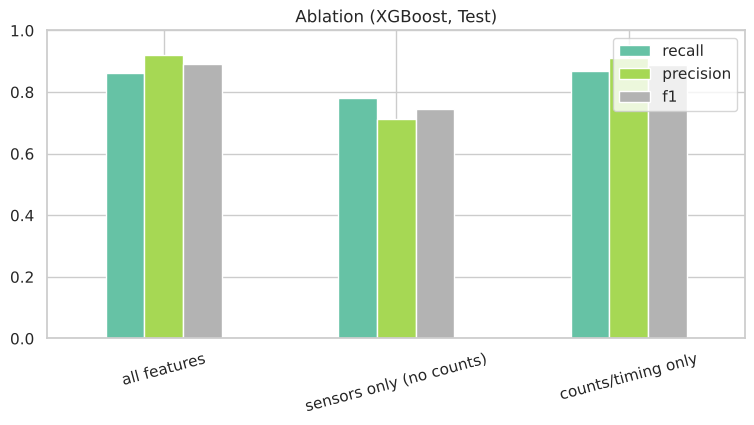

,recall,precision,f1
all features,0.863,0.920,0.890
sensors only (no counts),0.782,0.712,0.745
counts/timing only,0.868,0.911,0.889


In [42]:

TIMING = [c for c in FEATURES if "n_records" in c or c == "gap_prev"]
def quick_f1(cols):
    m = fit("XGBoost", make_models(spw)["XGBoost"], X[cols].iloc[train], y_tr, X[cols].iloc[val], y_va)
    th_ = best_threshold(y_va, m.predict_proba(X[cols].iloc[val])[:, 1])
    pr = m.predict_proba(X[cols].iloc[test])[:, 1] >= th_
    return dict(recall=recall_score(y_te, pr), precision=precision_score(y_te, pr), f1=f1_score(y_te, pr))

abl = pd.DataFrame({"all features": quick_f1(FEATURES),
                    "sensors only (no counts)": quick_f1([c for c in FEATURES if c not in TIMING]),
                    "counts/timing only": quick_f1(TIMING)}).T.round(3)
abl.plot.bar(rot=15, figsize=(9, 4), colormap="Set2"); plt.ylim(0, 1); plt.title("Ablation (XGBoost, Test)"); plt.show()
abl

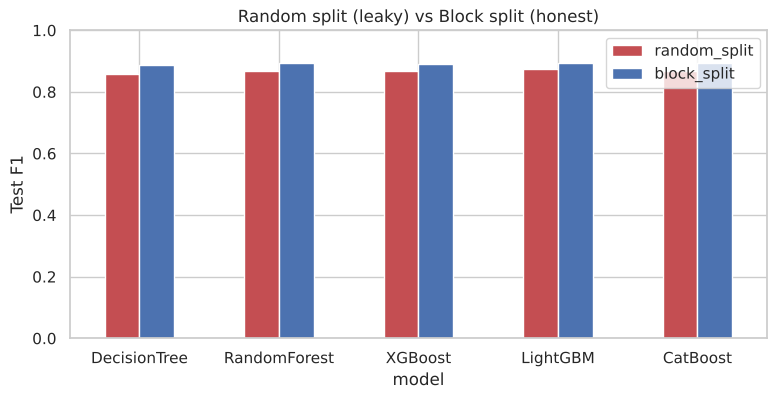

              random_split  block_split
model                                  
DecisionTree         0.859        0.886
RandomForest         0.867        0.895
XGBoost              0.869        0.890
LightGBM             0.873        0.894
CatBoost             0.869        0.894


In [43]:
a, b = train_test_split(all_idx, test_size=0.2, stratify=y, random_state=SEED)
a, v = train_test_split(a, test_size=0.2, stratify=y[a], random_state=SEED)

rows = []
for name, m in make_models(spw).items():
    m = fit(name, m, X.iloc[a], y[a], X.iloc[v], y[v])
    th_ = best_threshold(y[v], m.predict_proba(X.iloc[v])[:, 1])
    rows.append(dict(model=name,
                     random_split=f1_score(y[b], m.predict_proba(X.iloc[b])[:, 1] >= th_),

                     block_split=f1_score(y_te, probs[name]["test"] >= probs[name]["th"])))
cmp = pd.DataFrame(rows).set_index("model").round(3)
cmp.plot.bar(rot=0, figsize=(9, 4), color=["#c44e52", "#4c72b0"])
plt.ylim(0, 1); plt.ylabel("Test F1"); plt.title("Random split (leaky) vs Block split (honest)"); plt.show()
print(cmp)

In [44]:
os.makedirs("results", exist_ok=True)
results.to_csv("results/binary_results.csv"); mc_results.to_csv("results/multiclass_results.csv")
abl.to_csv("results/ablation.csv"); cv_summary.to_csv("results/cv_summary.csv"); per_class.to_csv("results/recall_per_attack_type.csv"); cmp.to_csv("results/random_vs_block.csv")
print("Saved in ./results")

Saved in ./results


# 9) Anomaly score (Z-score, Mahalanobis, Isolation Forest, Autoencoder)

In [45]:
from sklearn.preprocessing import StandardScaler
from sklearn.covariance import EmpiricalCovariance
from sklearn.ensemble import IsolationForest

norm_tr = train[y[train] == 0]                      # Normal windows of the train set only

def to_percentile(raw):
    # convert a raw score to 0..1 (percentile compared with Normal train windows)
    ref = np.sort(raw[norm_tr])
    return np.searchsorted(ref, raw) / len(ref)

# 1) Z-score: average distance (in standard deviations) from the Normal mean
sc = StandardScaler().fit(X.iloc[norm_tr])
raw_z = np.abs(sc.transform(X)).mean(axis=1)

# 2) Mahalanobis: distance from the Normal distribution (uses correlation between features)
cov = EmpiricalCovariance().fit(X.iloc[norm_tr])
raw_m = cov.mahalanobis(X)

# 3) Isolation Forest
iso = IsolationForest(n_estimators=200, random_state=SEED, n_jobs=-1).fit(X.iloc[norm_tr])
raw_i = -iso.score_samples(X)

scores = {"Z-score": to_percentile(raw_z),
          "Mahalanobis": to_percentile(raw_m),
          "IsolationForest": to_percentile(raw_i)}
print("done:", list(scores))

done: ['Z-score', 'Mahalanobis', 'IsolationForest']


In [46]:
# Autoencoder anomaly score: learns to rebuild Normal windows, the reconstruction error is the score
from sklearn.neural_network import MLPRegressor

sc_ae = StandardScaler().fit(X.iloc[norm_tr])       # fit on Normal train windows only
Xn = sc_ae.transform(X.iloc[norm_tr])

ae = MLPRegressor(hidden_layer_sizes=(32, 16, 8, 16, 32), activation="relu", solver="adam",
                  max_iter=200, early_stopping=True, n_iter_no_change=10, random_state=SEED)
ae.fit(Xn, Xn)                                      # input = target

X_all = sc_ae.transform(X)
raw_ae = ((X_all - ae.predict(X_all)) ** 2).mean(axis=1)   # mean squared reconstruction error

scores["Autoencoder"] = to_percentile(raw_ae)
print("done:", list(scores))

done: ['Z-score', 'Mahalanobis', 'IsolationForest', 'Autoencoder']


In [47]:
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve, precision_recall_curve,
                             recall_score, precision_score, f1_score, confusion_matrix)

ths = np.linspace(0.01, 0.99, 99)
# threshold of each model: best F1 on validation only
th_an = {nm: ths[np.argmax([f1_score(y[val], s[val] >= t) for t in ths])] for nm, s in scores.items()}

rows = []
for nm, s in scores.items():
    for split_nm, ii in (("val", val), ("test", test)):
        pred = s[ii] >= th_an[nm]
        rows.append(dict(model=nm, split=split_nm, threshold=round(th_an[nm], 2),
                         auc=roc_auc_score(y[ii], s[ii]),
                         avg_precision=average_precision_score(y[ii], s[ii]),
                         baseline_ap=y[ii].mean(),                    # AP of a random score = attack rate
                         recall=recall_score(y[ii], pred),
                         precision=precision_score(y[ii], pred, zero_division=0),
                         f1=f1_score(y[ii], pred)))
anom_results = pd.DataFrame(rows).set_index(["model", "split"]).round(3)
anom_results

threshold    auc  avg_precision  baseline_ap  recall  \
model           split                                                         
Z-score         val         0.35  0.563          0.258        0.252   0.825   
                test        0.35  0.593          0.372        0.350   0.877   
Mahalanobis     val         0.41  0.577          0.263        0.252   0.791   
                test        0.41  0.598          0.374        0.350   0.844   
IsolationForest val         0.44  0.632          0.288        0.252   0.848   
                test        0.44  0.636          0.400        0.350   0.874   
Autoencoder     val         0.35  0.555          0.255        0.252   0.805   
                test        0.35  0.583          0.368        0.350   0.856   

                       precision     f1  
model           split                    
Z-score         val        0.299  0.439  
                test       0.415  0.564  
Mahalanobis     val        0.310  0.445  
                test       0.426  0.566  
IsolationForest val        0.339  0.485  
                test       0.435  0.580  
Autoencoder     val        0.295  0.431  
                test       0.410  0.555

In [48]:
# Pick the anomaly method with the best validation F1 and keep what is needed to reuse it
best_an = anom_results.xs("val", level="split")["f1"].idxmax()
anomaly = scores[best_an]
print("Anomaly method:", best_an)

Anomaly method: IsolationForest


# 10) Baseline models (Alsaedi et al.)
Eight classic models, trained on **exactly the same windows, features and split** as the main models, and evaluated at the same levels:
**binary** (attack vs normal) and **multi-class** (attack type), for this device (Fridge).

| Model | Setup | Preprocessing |
|---|---|---|
| Logistic Regression (LR) | linear, `class_weight=balanced` | StandardScaler |
| Linear Discriminant Analysis (LDA) | linear boundary | none (scale-invariant) |
| k-Nearest Neighbour (kNN) | k=5 | StandardScaler (distance based) |
| CART | single decision tree (Gini) | none |
| Random Forest (RF) | 10 trees | none |
| Naïve Bayes (NB) | Gaussian, probabilistic | none |
| SVM (RBF kernel) | `class_weight=balanced` | StandardScaler |
| LSTM | deep model on the last 4 windows | log(n_records) + StandardScaler, sequences of 4 windows |

The scaler is fitted on the **train** windows only. Thresholds are chosen on **validation** only.

In [49]:
# ---------- Baselines: setup, preprocessing, LSTM wrapper ----------
import copy, torch, torch.nn as nn
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, average_precision_score, classification_report

torch.set_num_threads(2)
os.makedirs("results/baselines", exist_ok=True)
K = len(classes)

# 1) Tabular preprocessing: StandardScaler fitted on TRAIN windows only (used by LR, kNN, SVM)
scaler_b = StandardScaler().fit(X.iloc[train])
XB_scaled, XB_raw = scaler_b.transform(X), X.values
SCALED = {"LR", "kNN", "SVM"}

# 2) LSTM input: the last T windows (current + 3 previous, same chunk; zeros where there is no history)
T = 4
SEQ_COLS = ["fridge_temperature_mean", "fridge_temperature_std", "fridge_temperature_min",
            "fridge_temperature_max", "frac_high", "n_records"]
seq_raw = W[SEQ_COLS].copy()
seq_raw["n_records"] = np.log1p(seq_raw["n_records"])                      # counts are very skewed
seq_sc = StandardScaler().fit(seq_raw.iloc[train])                          # train statistics only
arr, ch = seq_sc.transform(seq_raw).astype("float32"), W["chunk"].values
XSEQ = np.zeros((len(W), T, len(SEQ_COLS)), dtype="float32")
for k in range(T):                                                          # k = 0 is the current window
    ok = np.ones(len(W), bool) if k == 0 else (np.arange(len(W)) >= k) & (np.roll(ch, k) == ch)
    XSEQ[:, T - 1 - k, :] = np.where(ok[:, None], np.roll(arr, k, axis=0), 0)
# the first 3 windows of every block are purged, so a kept window never sees another block's data

class _LSTMNet(nn.Module):
    def __init__(self, n_in, hidden, n_out):
        super().__init__(); self.lstm = nn.LSTM(n_in, hidden, batch_first=True); self.fc = nn.Linear(hidden, n_out)
    def forward(self, x):
        o, _ = self.lstm(x); return self.fc(o[:, -1, :])

class LSTMClf:
    """Small LSTM with early stopping on validation loss (sklearn-like API)."""
    def __init__(self, n_classes, hidden=32, epochs=40, patience=6, lr=1e-3, batch=256):
        self.K, self.hidden, self.epochs, self.patience, self.lr, self.batch = n_classes, hidden, epochs, patience, lr, batch
    def _loss(self, ytr):
        if self.K == 2:
            return nn.BCEWithLogitsLoss(pos_weight=torch.tensor(float((ytr == 0).sum() / max((ytr == 1).sum(), 1))))
        bc = np.bincount(ytr, minlength=self.K)
        return nn.CrossEntropyLoss(weight=torch.tensor(len(ytr) / (self.K * np.maximum(bc, 1)), dtype=torch.float32))
    def _out(self, z, y):
        return (z.squeeze(1), y.float()) if self.K == 2 else (z, y.long())
    def fit(self, Xtr, ytr, Xva, yva):
        torch.manual_seed(SEED); np.random.seed(SEED)
        self.net = _LSTMNet(Xtr.shape[2], self.hidden, 1 if self.K == 2 else self.K)
        opt, lossf = torch.optim.Adam(self.net.parameters(), lr=self.lr), self._loss(ytr)
        Xt, yt, Xv, yv = map(torch.tensor, (Xtr, ytr, Xva, yva))
        best, best_state, bad = np.inf, None, 0
        for ep in range(self.epochs):
            self.net.train()
            for b in torch.randperm(len(Xt)).split(self.batch):
                opt.zero_grad(); lossf(*self._out(self.net(Xt[b]), yt[b])).backward(); opt.step()
            self.net.eval()
            with torch.no_grad(): vl = lossf(*self._out(self.net(Xv), yv)).item()
            if vl < best - 1e-4: best, best_state, bad = vl, copy.deepcopy(self.net.state_dict()), 0
            else:
                bad += 1
                if bad >= self.patience: break
        self.net.load_state_dict(best_state); self.epochs_run = ep + 1
        return self
    def predict_proba(self, Xn):
        self.net.eval()
        with torch.no_grad():
            z = torch.cat([self.net(torch.tensor(Xn[i:i + 4096])) for i in range(0, len(Xn), 4096)])
            if self.K == 2:
                p = torch.sigmoid(z.squeeze(1)).numpy(); return np.c_[1 - p, p]
            return torch.softmax(z, 1).numpy()
    def predict(self, Xn): return self.predict_proba(Xn).argmax(1)

def baseline_models(n_classes):
    return {
        "LR":   LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED),
        "LDA":  LinearDiscriminantAnalysis(),
        "kNN":  KNeighborsClassifier(n_neighbors=5, n_jobs=-1),
        "CART": DecisionTreeClassifier(class_weight="balanced", random_state=SEED),
        "RF":   RandomForestClassifier(n_estimators=10, class_weight="balanced_subsample", n_jobs=-1, random_state=SEED),
        "NB":   GaussianNB(),
        "SVM":  SVC(kernel="rbf", class_weight="balanced", random_state=SEED),
        "LSTM": LSTMClf(n_classes),
    }

def model_input(name):
    return XSEQ if name == "LSTM" else (XB_scaled if name in SCALED else XB_raw)

def fit_any(name, m, Xin, ytr_, yva_):
    return m.fit(Xin[train], ytr_, Xin[val], yva_) if name == "LSTM" else m.fit(Xin[train], ytr_)

print("Sequences:", XSEQ.shape, "| tabular:", XB_raw.shape)

Sequences: (51047, 4, 6) | tabular: (51047, 28)


In [50]:
# ---------- Baselines: BINARY (attack vs normal) ----------
def bin_score(m, Xin):
    return m.predict_proba(Xin)[:, 1] if hasattr(m, "predict_proba") else m.decision_function(Xin)

def best_thr_any(y_true, s):
    # threshold with the best F1 on validation; candidates are quantiles of the validation scores
    cand = np.unique(np.quantile(s, np.linspace(0.02, 0.98, 97)))
    return cand[int(np.argmax([f1_score(y_true, s >= t) for t in cand]))]

SPLITS = (("train", train, y_tr), ("val", val, y_va), ("test", test, y_te))
bl_bin_rows, bl_scores, bl_cm = [], {}, {}
for name, m in baseline_models(2).items():
    Xin = model_input(name)
    m = fit_any(name, m, Xin, y_tr, y_va)
    sc = {sp: bin_score(m, Xin[idx]) for sp, idx, _ in SPLITS}
    th_b = float(best_thr_any(y_va, sc["val"]))
    bl_scores[name] = dict(sc, th=th_b)
    for sp, idx, yt in SPLITS:
        pr = sc[sp] >= th_b
        bl_bin_rows.append(dict(model=name, split=sp, threshold=th_b, accuracy=accuracy_score(yt, pr),
                                precision=precision_score(yt, pr, zero_division=0), recall=recall_score(yt, pr),
                                f1=f1_score(yt, pr), auc=roc_auc_score(yt, sc[sp]),
                                avg_precision=average_precision_score(yt, sc[sp])))
    tn, fp, fn, tp = confusion_matrix(y_te, sc["test"] >= th_b).ravel()
    bl_cm[name] = dict(TN=int(tn), FP=int(fp), FN=int(fn), TP=int(tp))
    print(name, "done")

bl_bin = pd.DataFrame(bl_bin_rows).set_index(["model", "split"]).round(3)
bl_bin_test = bl_bin.xs("test", level="split")
bl_bin_test_f1 = bl_bin.reset_index().pivot(index="model", columns="split", values="f1")[["train", "val", "test"]]
bl_bin_test_f1["gap (train-test)"] = bl_bin_test_f1["train"] - bl_bin_test_f1["test"]
display(bl_bin_test.sort_values("f1", ascending=False))
display(bl_bin_test_f1.round(3))

LR done


LDA done


kNN done


CART done


RF done
NB done


SVM done


LSTM done


,threshold,accuracy,precision,recall,f1,auc,avg_precision
model,,,,,,,
LSTM,0.553,0.929,0.935,0.856,0.894,0.968,0.941
RF,0.600,0.925,0.927,0.853,0.889,0.953,0.920
CART,1.000,0.868,0.799,0.832,0.816,0.860,0.724
SVM,-0.269,0.672,0.517,0.967,0.674,0.748,0.503
NB,1.000,0.645,0.497,0.961,0.655,0.703,0.458
LR,0.386,0.637,0.491,0.951,0.647,0.621,0.382
LDA,0.262,0.533,0.419,0.861,0.564,0.568,0.352
kNN,0.200,0.502,0.399,0.830,0.539,0.609,0.421


split,train,val,test,gap (train-test)
model,,,,
CART,1.000,0.754,0.816,0.184
LDA,0.529,0.435,0.564,-0.035
LR,0.601,0.506,0.647,-0.046
LSTM,0.863,0.867,0.894,-0.031
NB,0.608,0.518,0.655,-0.047
RF,0.982,0.858,0.889,0.093
SVM,0.630,0.547,0.674,-0.044
kNN,0.607,0.420,0.539,0.068


In [51]:
# ---------- Baselines: MULTI-CLASS (attack type) ----------
from sklearn.metrics import precision_recall_fscore_support
MC_SPLITS = (("train", train, yc_tr), ("val", val, yc_va), ("test", test, yc_te))
bl_mc_rows, bl_mc_pred, bl_perclass = [], {}, {}
for name, m in baseline_models(K).items():
    Xin = model_input(name)
    m = fit_any(name, m, Xin, yc_tr, yc_va)
    bl_mc_pred[name] = {}
    for sp, idx, yt in MC_SPLITS:
        pr = np.asarray(m.predict(Xin[idx])).ravel().astype(int); bl_mc_pred[name][sp] = pr
        lab = sorted(set(yt))                                   # only the classes that exist in this split
        bl_mc_rows.append(dict(model=name, split=sp, accuracy=accuracy_score(yt, pr),
                               macro_precision=precision_score(yt, pr, labels=lab, average="macro", zero_division=0),
                               macro_recall=recall_score(yt, pr, labels=lab, average="macro", zero_division=0),
                               macro_f1=f1_score(yt, pr, labels=lab, average="macro", zero_division=0),
                               weighted_f1=f1_score(yt, pr, labels=lab, average="weighted", zero_division=0)))
    rep = classification_report(yc_te, bl_mc_pred[name]["test"], labels=present,
                                target_names=[classes[i] for i in present], output_dict=True, zero_division=0)
    bl_perclass[name] = pd.DataFrame(rep).T.loc[[classes[i] for i in present]][["precision", "recall", "f1-score", "support"]]
    print(name, "done")

bl_mc = pd.DataFrame(bl_mc_rows).set_index(["model", "split"]).round(3)
display(bl_mc.xs("test", level="split").sort_values("macro_f1", ascending=False))
bl_perclass_all = pd.concat(bl_perclass, names=["model", "class"]).round(3)
display(bl_perclass_all["recall"].unstack("model"))        # recall per attack type, test set

LR done
LDA done


kNN done


CART done


RF done
NB done


SVM done


LSTM done


,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1
model,,,,,
RF,0.886,0.619,0.538,0.538,0.873
CART,0.807,0.513,0.511,0.497,0.812
LSTM,0.543,0.527,0.495,0.483,0.625
NB,0.273,0.422,0.395,0.264,0.199
kNN,0.609,0.264,0.202,0.200,0.543
SVM,0.190,0.324,0.307,0.200,0.180
LR,0.219,0.298,0.271,0.196,0.276
LDA,0.619,0.121,0.173,0.142,0.500


model,LR,LDA,kNN,CART,RF,NB,SVM,LSTM
class,,,,,,,,
backdoor,0.426,0.000,0.120,0.710,0.846,0.999,0.572,0.937
ddos,0.851,0.088,0.118,0.584,0.603,0.809,0.821,0.714
injection,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
normal,0.137,0.949,0.883,0.888,0.969,0.004,0.029,0.419
password,0.171,0.000,0.088,0.768,0.801,0.535,0.304,0.621
ransomware,0.043,0.000,0.000,0.117,0.009,0.022,0.117,0.277


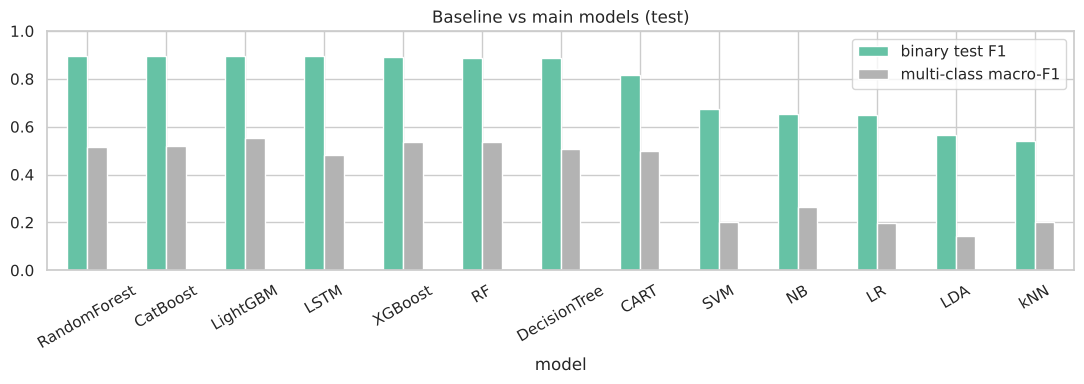

Saved baseline results in ./results and figures in ./results/baselines


,binary test F1,multi-class macro-F1,group
model,,,
RandomForest,0.895,0.514,main
CatBoost,0.894,0.521,main
LightGBM,0.894,0.552,main
LSTM,0.894,0.483,baseline
XGBoost,0.890,0.534,main
RF,0.889,0.538,baseline
DecisionTree,0.886,0.508,main
CART,0.816,0.497,baseline
SVM,0.674,0.200,baseline


In [52]:
# ---------- Baselines: one figure per model + comparison + save ----------
for name in baseline_models(2):
    d = bl_scores[name]
    fig, ax = plt.subplots(1, 3, figsize=(14, 4))
    c = confusion_matrix(y_te, d["test"] >= d["th"])
    sns.heatmap(c, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax[0],
                xticklabels=["Normal", "Attack"], yticklabels=["Normal", "Attack"])
    ax[0].set_xlabel("Predicted"); ax[0].set_ylabel("Actual"); ax[0].set_title("Binary confusion matrix (test)")
    fpr, tpr, _ = roc_curve(y_te, d["test"]); ax[1].plot(fpr, tpr); ax[1].plot([0, 1], [0, 1], "k--", lw=0.7)
    ax[1].set_title(f"ROC (AUC {roc_auc_score(y_te, d['test']):.3f})"); ax[1].set_xlabel("FPR"); ax[1].set_ylabel("TPR")
    p, r, _ = precision_recall_curve(y_te, d["test"]); ax[2].plot(r, p)
    ax[2].set_title(f"Precision-Recall (AP {average_precision_score(y_te, d['test']):.3f})")
    ax[2].set_xlabel("Recall"); ax[2].set_ylabel("Precision")
    fig.suptitle(f"{name} - binary", y=1.02); plt.tight_layout()
    plt.savefig(f"results/baselines/{name}_binary.png", dpi=130, bbox_inches="tight"); plt.close(fig)

    fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
    cmn = confusion_matrix(yc_te, bl_mc_pred[name]["test"], labels=range(K))[present]
    cmn = cmn / np.maximum(cmn.sum(axis=1, keepdims=True), 1)
    sns.heatmap(cmn, annot=True, fmt=".2f", cmap="Blues", ax=ax[0], xticklabels=classes,
                yticklabels=[classes[i] for i in present])
    ax[0].set_xlabel("Predicted"); ax[0].set_ylabel("Actual"); ax[0].set_title("Multi-class confusion matrix (test, row-normalised)")
    bl_perclass[name][["precision", "recall", "f1-score"]].plot.bar(ax=ax[1], rot=30, ylim=(0, 1.05), colormap="Set2")
    ax[1].set_title("Per-class precision / recall / F1 (test)")
    fig.suptitle(f"{name} - multi-class", y=1.02); plt.tight_layout()
    plt.savefig(f"results/baselines/{name}_multiclass.png", dpi=130, bbox_inches="tight"); plt.close(fig)

# comparison with the 5 main models (test F1 for binary, macro-F1 for multi-class)
comp = pd.concat([
    bl_bin.xs("test", level="split")["f1"].rename("binary test F1"),
    bl_mc.xs("test", level="split")["macro_f1"].rename("multi-class macro-F1")], axis=1)
main_b = results[results.split == "test"].set_index("model")["f1"].rename("binary test F1")
main_m = mc_results["macro_f1"].rename("multi-class macro-F1")
comp_all = pd.concat([comp.assign(group="baseline"), pd.concat([main_b, main_m], axis=1).assign(group="main")])
comp_all = comp_all.sort_values("binary test F1", ascending=False)
comp_all[["binary test F1", "multi-class macro-F1"]].plot.bar(figsize=(11, 4), rot=30, colormap="Set2")
plt.ylim(0, 1); plt.title("Baseline vs main models (test)"); plt.tight_layout(); plt.show()

bl_bin.to_csv("results/baselines_binary.csv"); bl_mc.to_csv("results/baselines_multiclass.csv")
bl_perclass_all.to_csv("results/baselines_per_class.csv"); pd.DataFrame(bl_cm).T.to_csv("results/baselines_confusion_binary.csv")
comp_all.to_csv("results/baselines_vs_main.csv")
print("Saved baseline results in ./results and figures in ./results/baselines")
comp_all.round(3)

# 11) Export

In [53]:
# Final export: unified detection events + config
import json, os
os.makedirs("export", exist_ok=True); os.makedirs("results", exist_ok=True)

SOURCE = "fridge"
mc_best = mc[best_mc]
th_final = float(th_cal)

# calibrated attack probability for every window (the same scale as th_final)
pa = calibrator.predict(models[best].predict_proba(X)[:, 1])
pred_type = le.inverse_transform(np.asarray(mc_best.predict(X)).ravel().astype(int))
is_attack_pred = pa >= th_final
# attack type only for windows predicted as Attack ("unknown" if the multi-class model says normal)
attack_type = np.where(is_attack_pred, np.where(pred_type != "normal", pred_type, "unknown"), "none")

# split column: train / val / test, or "purged" for edge windows (used only to filter them out)
split = np.full(len(W), "purged", dtype=object)
for idx, key in ((train, "train"), (val, "val"), (test, "test")):
    split[idx] = key

events = pd.DataFrame({
    "source": SOURCE,
    "window_start": pd.Timestamp("2019-01-01") + pd.to_timedelta(W["win"] * 10, unit="s"),
    "prediction": np.where(is_attack_pred, "Attack", "Normal"),
    "attack_prob": pa,
    "attack_type": attack_type,
    "anomaly_score": anomaly,
    "n_records": W["n_records"].values,
    "true_label": W["is_attack"].values,
    "split": split,
})
# purged edge windows are NOT written to the events file (per the spec)
keep = split != "purged"
events = events.loc[keep].copy()
events.insert(0, "event_id", np.arange(len(events), dtype=int))
events.to_csv(f"export/{SOURCE}_events.csv", index=False)
anom_results.to_csv("results/anomaly_results.csv")

# predictions file (purged windows removed). p_attack is the calibrated probability, so
# "p_attack >= threshold" in the config gives exactly the predictions above.
export_df = pd.DataFrame({"source": SOURCE, "chunk": W["chunk"], "win": W["win"], "split": split,
                          "p_attack": pa, "y_true": W["is_attack"], "true_type": W["type"],
                          "pred_type": pred_type, "n_records": W["n_records"]})
export_df[export_df["split"] != "purged"].to_csv(f"export/{SOURCE}_predictions.csv", index=False)

# recall target chosen on validation (calibrated probabilities): the highest threshold with val recall >= target
RECALL_TARGET = 0.90
ths_r = np.linspace(0.01, 0.99, 99)
ok = [t for t in ths_r if recall_score(y_va, p_cal_va >= t) >= RECALL_TARGET]
th_recall = float(max(ok)) if ok else float(ths_r[0])

cfg = {"source": SOURCE, "binary_model": best, "multiclass_model": best_mc, "calibrated": True,
       "threshold": th_final, "recall_target": RECALL_TARGET, "threshold_recall": th_recall,
       "anomaly_method": best_an, "features": FEATURES, "classes": classes,
       "window_seconds": 10, "epoch": "2019-01-01", "block_windows": BLOCK,
       "split_rule": {"method": "md5 hash of block number", "salt": SALT, "train_pct": TRAIN_PCT, "val_pct": VAL_PCT},
       "val_f1": float(f1_score(y_va, p_cal_va >= th_final)),
       "test_f1": float(f1_score(y_te, p_cal_te >= th_final))}

CONFIG_KEYS = ["source", "binary_model", "multiclass_model", "calibrated", "threshold", "recall_target",
               "threshold_recall", "anomaly_method", "features", "classes", "window_seconds", "epoch",
               "block_windows", "split_rule", "val_f1", "test_f1"]
assert list(cfg.keys()) == CONFIG_KEYS, "config keys differ from CONFIG_KEYS"

with open(f"export/{SOURCE}_config.json", "w") as f:
    json.dump(cfg, f, indent=2)

# ---------- read-back checks ----------
EVENT_COLS = ["event_id", "source", "window_start", "prediction", "attack_prob", "attack_type",
              "anomaly_score", "n_records", "true_label", "split"]
with open(f"export/{SOURCE}_config.json") as f:
    cfg_rb = json.load(f)
assert list(cfg_rb.keys()) == CONFIG_KEYS and cfg_rb == cfg, "config read-back mismatch"

ev_rb = pd.read_csv(f"export/{SOURCE}_events.csv")
pr_rb = pd.read_csv(f"export/{SOURCE}_predictions.csv")
assert list(ev_rb.columns) == EVENT_COLS, "events columns differ from the spec"
assert "purged" not in set(ev_rb["split"]), "purged rows must not be in the events file"
assert (ev_rb["event_id"].values == np.arange(len(ev_rb))).all(), "event_id must be 0..n-1"
assert len(ev_rb) == len(pr_rb) == int(keep.sum()), "events / predictions row counts differ"
assert set(ev_rb["split"]) <= {"train", "val", "test"}
assert ev_rb["attack_prob"].between(0, 1).all() and ev_rb["anomaly_score"].between(0, 1).all()
assert ((pr_rb["p_attack"] >= cfg_rb["threshold"]).values == (ev_rb["prediction"] == "Attack").values).all(), \
    "p_attack >= threshold must reproduce the events predictions"
assert pr_rb["split"].isin(["train", "val", "test"]).all()
print("Export checks passed")

print(cfg["binary_model"], cfg["multiclass_model"], best_an, "| test F1:", round(cfg["test_f1"], 3))
print(events.groupby("split").size().to_dict())
events.head()


Export checks passed
LightGBM LightGBM IsolationForest | test F1: 0.894
{'test': 7245, 'train': 33908, 'val': 6819}


,event_id,source,window_start,prediction,attack_prob,attack_type,anomaly_score,n_records,true_label,split
2,0,fridge,2019-03-31 12:37:10,Normal,0.015603,none,0.926203,50,0,train
3,1,fridge,2019-03-31 12:37:20,Normal,0.015603,none,0.798631,70,0,train
4,2,fridge,2019-03-31 12:37:30,Normal,0.015603,none,0.820933,85,0,train
5,3,fridge,2019-03-31 12:37:40,Normal,0.015603,none,0.847412,106,0,train
6,4,fridge,2019-03-31 12:37:50,Normal,0.015603,none,0.838242,113,0,train
